# Import the Data

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import keras

from keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.utils import compute_class_weight

# Loading the Data

In [2]:
train_df = keras.utils.image_dataset_from_directory(
    'emotions/train',
    image_size=(48, 48),
    seed=43
)

test_df=keras.utils.image_dataset_from_directory(
    'emotions/test',
    image_size=(48, 48),
    seed=42, 
    shuffle = False
)

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.


# Inspecting the Data

In [3]:
x_list = []
y_list = []

for x, y in train_df:
    x_list.append(x.numpy())
    y_list.append(y.numpy())

x_train = np.concatenate(x_list)
y_train = np.concatenate(y_list)
x_train = x_train / 255

In [4]:
x_test_list = []
y_test_list = []

for x, y in test_df:
    x_test_list.append(x.numpy())
    y_test_list.append(y.numpy())

x_test = np.concatenate(x_test_list)
y_test = np.concatenate(y_test_list)
x_test = x_test / 255

In [5]:
train_df.class_names

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

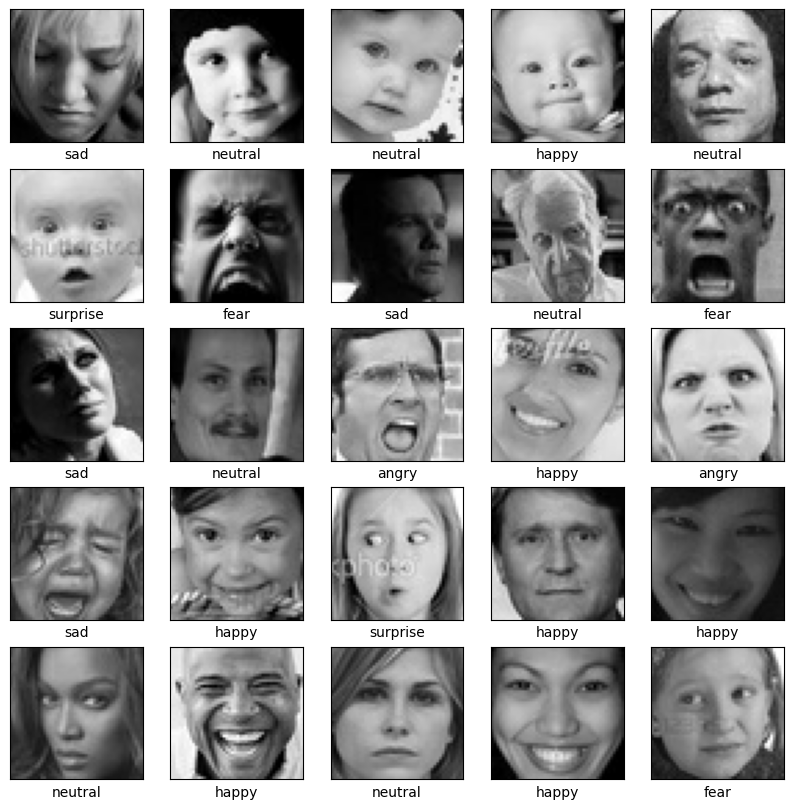

In [6]:
class_names = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[i])
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(class_names[y_train[i]])
plt.show()

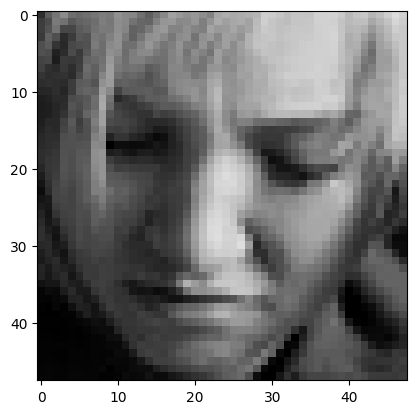

In [7]:
plt.imshow(x_train[0])

# Baseline Model 

In [8]:
from keras.layers import Dense, Activation, Flatten
from keras.models import Sequential
from keras.utils import set_random_seed
import random
import numpy as np

seed = 9999
set_random_seed(seed)

model = Sequential([
    Flatten(input_shape=(48,48,3)),
    Dense(128,  activation='relu' ),
    
    
    Dense(7, activation='softmax')
    
])
model.summary()

C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 6912)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         884,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 885,767 (3.38 MB)

 Trainable params: 885,767 (3.38 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# STep3: Compile
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])


#STep4: Fitting

history2 = model.fit(x_train, y_train, validation_split=0.2, epochs=15, shuffle= False)

Epoch 1/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.2197 - loss: 2.5071 - val_accuracy: 0.2435 - val_loss: 1.8568
Epoch 2/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.2748 - loss: 1.8524 - val_accuracy: 0.2602 - val_loss: 1.8583
Epoch 3/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.3074 - loss: 1.7443 - val_accuracy: 0.3257 - val_loss: 1.7140
Epoch 4/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.3215 - loss: 1.7093 - val_accuracy: 0.3349 - val_loss: 1.7000
Epoch 5/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.3334 - loss: 1.6897 - val_accuracy: 0.3314 - val_loss: 1.6981
Epoch 6/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.3404 - loss: 1.6794 - val_accuracy: 0.3405 - val_loss: 1.6889
Epoch 7/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.3455 - loss: 1.6704 - val_accuracy: 0.3258 - val_loss: 1.7377
Epoch 8/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.3512 - loss: 1.6625 - val_accuracy: 0

In [10]:
history_df = pd.DataFrame(history2.history)
history_df

,accuracy,loss,val_accuracy,val_loss
0,0.219707,2.507128,0.243469,1.856823
1,0.274786,1.852401,0.260188,1.858312
2,0.307354,1.744311,0.325671,1.714012
3,0.321548,1.709348,0.334901,1.699957
4,0.333435,1.689663,0.331418,1.698088
5,0.340401,1.679405,0.340474,1.688877
6,0.345539,1.670394,0.325845,1.737715
7,0.351243,1.662461,0.335772,1.715698
8,0.352245,1.656452,0.305991,1.857555
9,0.354030,1.652043,0.338210,1.694250


<Axes: >

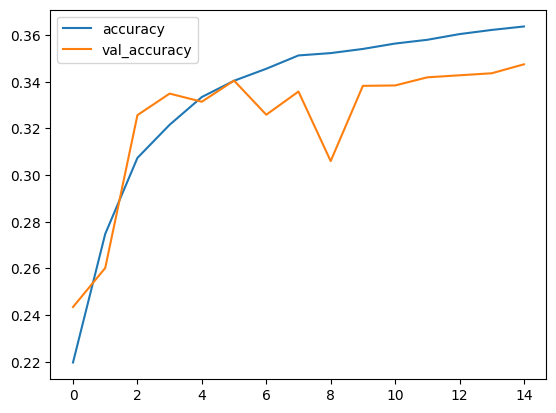

In [11]:
history_df[['accuracy', 'val_accuracy']].plot()

# Model 2

In [12]:
early_stoping_callback = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [13]:
pd.Series(y_train).value_counts()

3    7215
4    4965
5    4830
2    4097
0    3995
6    3171
1     436
Name: count, dtype: int64

In [14]:
c_weights = compute_class_weight(class_weight="balanced",
                                 classes=np.unique(y_train),
                                 y=y_train)
c_weights

array([1.02660468, 9.40661861, 1.00104606, 0.56843877, 0.82603942,
       0.84912748, 1.29337298])

In [42]:
class_weight_dict = dict(zip(np.unique(y_train), (c_weights)))
class_weight_dict

{np.int32(0): np.float64(1.0266046844269623),
 np.int32(1): np.float64(9.406618610747051),
 np.int32(2): np.float64(1.0010460615781582),
 np.int32(3): np.float64(0.5684387684387684),
 np.int32(4): np.float64(0.8260394187886635),
 np.int32(5): np.float64(0.8491274770777877),
 np.int32(6): np.float64(1.293372978330405)}

In [43]:
set_random_seed(seed)

model2 = Sequential([
    Flatten(input_shape=(48,48,3)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(7, activation='softmax')
])

C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [44]:
model2.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model2.fit(x_train, y_train, validation_split=0.2, epochs=30, shuffle=False, class_weight=class_weight_dict, callbacks=early_stoping_callback)

Epoch 1/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.1717 - loss: 2.0670 - val_accuracy: 0.2656 - val_loss: 1.8712
Epoch 2/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.2625 - loss: 1.8892 - val_accuracy: 0.1808 - val_loss: 2.5704
Epoch 3/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.2628 - loss: 1.8773 - val_accuracy: 0.2905 - val_loss: 1.8199
Epoch 4/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.2594 - loss: 1.8702 - val_accuracy: 0.2987 - val_loss: 1.8131
Epoch 5/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.2433 - loss: 1.8637 - val_accuracy: 0.2572 - val_loss: 1.8198
Epoch 6/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.2348 - loss: 1.8640 - val_accuracy: 0.2621 - val_loss: 1.8069
Epoch 7/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.2278 - loss: 1.8500 - val_accuracy: 0.2198 - val_loss: 1.8415
Epoch 8/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.2301 - loss: 1.8504 - 

In [45]:
history_df = pd.DataFrame(history.history)
history_df


,accuracy,loss,val_accuracy,val_loss
0,0.171681,2.066992,0.265587,1.871227
1,0.262464,1.889243,0.180773,2.570423
2,0.262768,1.877346,0.290491,1.819942
3,0.259372,1.870236,0.298676,1.813069
4,0.243349,1.863663,0.257227,1.819836
5,0.234815,1.863966,0.262104,1.806912
6,0.227849,1.850018,0.219784,1.841526
7,0.230113,1.850398,0.221526,1.841755
8,0.229155,1.841623,0.260536,1.811587
9,0.233204,1.840869,0.261059,1.815345


<Axes: >

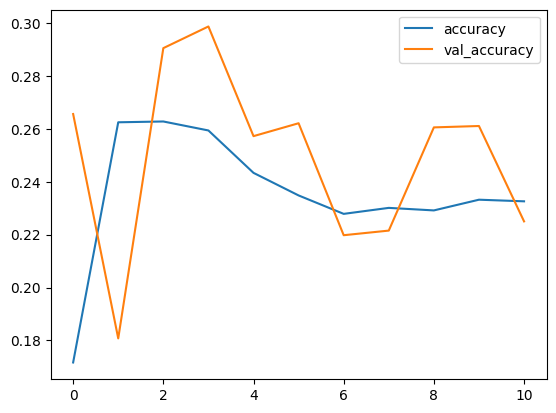

In [46]:
history_df[['accuracy', 'val_accuracy']].plot()

# check model 1

In [20]:
y_pred_test = model.predict(x_test).argmax(axis=1) # axis=1 means row-wise 
y_pred_test

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([3, 5, 3, ..., 4, 6, 6], shape=(7178,))

In [21]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.18      0.03      0.05       958
           1       0.00      0.00      0.00       111
           2       0.15      0.04      0.07      1024
           3       0.49      0.59      0.54      1774
           4       0.28      0.61      0.38      1233
           5       0.28      0.27      0.28      1247
           6       0.49      0.42      0.45       831

    accuracy                           0.36      7178
   macro avg       0.27      0.28      0.25      7178
weighted avg       0.32      0.36      0.31      7178



C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

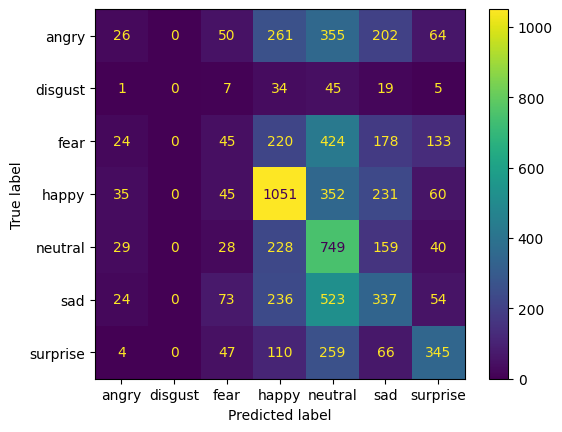

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

confusion_matrix(y_test, y_pred_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test,display_labels= test_df.class_names )

# check model 2

In [47]:
y_pred_test = model2.predict(x_test).argmax(axis=1) # axis=1 means row-wise 
y_pred_test

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


array([3, 1, 3, ..., 1, 6, 6], shape=(7178,))

In [48]:
# what is the accuracy?
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.23      0.04      0.06       958
           1       0.02      0.34      0.04       111
           2       0.17      0.03      0.05      1024
           3       0.38      0.70      0.49      1774
           4       0.30      0.09      0.13      1233
           5       0.31      0.07      0.11      1247
           6       0.38      0.54      0.45       831

    accuracy                           0.28      7178
   macro avg       0.26      0.26      0.19      7178
weighted avg       0.30      0.28      0.23      7178



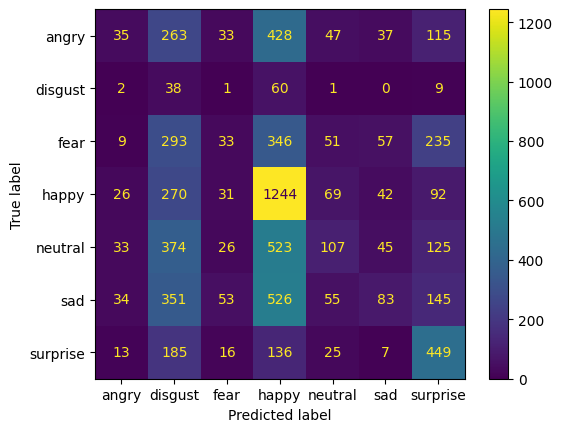

In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

confusion_matrix(y_test, y_pred_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test,display_labels= test_df.class_names )

# Prediction

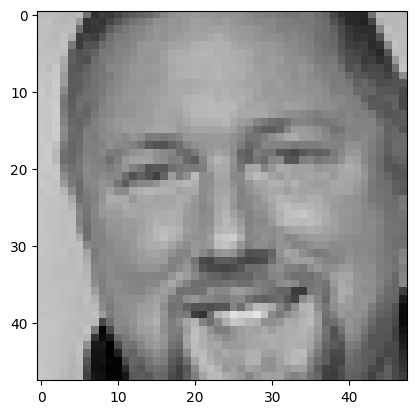

In [96]:
plt.imshow(x_test[3000])

In [97]:
pred_first_img = model2.predict(x_test[3000:3001])
pred_first_img

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


array([[0.15076368, 0.1474555 , 0.11806794, 0.26581153, 0.12761213,
        0.13628994, 0.05399921]], dtype=float32)

In [98]:
class_names[np.argmax(pred_first_img)]

'happy'

In [99]:
class_names[y_test[3000]]

'happy'

# Model Saving

In [100]:
model2.save('emotions_model.keras')